In [6]:
# ============================================
# FinMark Corporation - Data Preparation & EDA
# ============================================

# Import libraries 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid", palette="muted") 
plt.rcParams['figure.figsize'] = (10,6)

In [7]:
# -----------------------------
# 1. Load datasets
# -----------------------------
product_df = pd.read_csv("Product_Offering_Data.csv") 
feedback_df = pd.read_csv("Customer_Feedback_Data.csv") 
transaction_df = pd.read_csv("Transaction_Data.csv")

# Load transaction data in chunks (for large files)
transaction_chunks = pd.read_csv("Transaction_Data.csv", chunksize=100000)
transaction_df = pd.concat(transaction_chunks)

print("Product Offering Data: ")
display(product_df.head())

print("Customer Feedback Data: ")
display(feedback_df.head())

print("Transaction Data: ")
display(transaction_df.head())

Product Offering Data: 


,Product_ID,Product_Name,Product_Type,Risk_Level,Target_Age_Group,Target_Income_Group
0,1,Platinum Credit Card,Credit Card,Medium,NaN,Medium
1,2,Gold Savings Account,Savings Account,Low,NaN,Low
2,3,High-Yield Investment Account,Investment,High,NaN,High
3,4,Mortgage Loan,Loan,Medium,NaN,High
4,5,Auto Loan,Loan,Medium,NaN,Medium


Customer Feedback Data: 


,Customer_ID,Satisfaction_Score,Feedback_Comments,Likelihood_to_Recommend
0,1,10.0,Very satisfied,9
1,2,3.0,Very satisfied,3
2,3,10.0,Very satisfied,1
3,4,7.0,Needs improvement,4
4,5,8.0,Unsatisfactory,7


Transaction Data: 


,Transaction_ID,Customer_ID,Transaction_Date,Transaction_Amount,Transaction_Type
0,1,393,2023-01-01 00:00:00,3472.0,Purchase
1,2,826,2023-01-01 01:00:00,NaN,Bill Payment
2,3,916,2023-01-01 02:00:00,10.0,Purchase
3,4,109,2023-01-01 03:00:00,72.0,Investment
4,5,889,2023-01-01 04:00:00,1793.0,Investment


In [10]:
# -----------------------------
# 2. Data Cleaning
# -----------------------------

## Product Cleaning
product_df = product_df.drop_duplicates()
if "Target_Age_Group" in product_df.columns:
    product_df = product_df.drop(columns=["Target_Age_Group"]) # entirely missing
product_df.reset_index(drop=True, inplace=True)

## Customer Feedback Cleaning
feedback_df = feedback_df.drop_duplicates(subset="Customer_ID", keep="first")
feedback_df["Satisfaction_Score"] = pd.to_numeric(feedback_df["Satisfaction_Score"], errors="coerce")
feedback_df["Satisfaction_Score"]= feedback_df["Satisfaction_Score"].fillna(feedback_df["Satisfaction_Score"].median())
feedback_df["Satisfaction_Score"] = feedback_df["Satisfaction_Score"].clip(lower=1, upper=10)

## Transaction Data Cleaning
transaction_df = transaction_df.drop_duplicates()
transaction_df["Transaction_Amount"] = pd.to_numeric(transaction_df["Transaction_Amount"], errors="coerce")
transaction_df["Transaction_Amount"] = transaction_df["Transaction_Amount"].fillna(0)
transaction_df["Transaction_Date"] = pd.to_datetime(transaction_df["Transaction_Date"], errors="coerce")

In [25]:
# -----------------------------
# 3. Feature Engineering
# -----------------------------

# Aggregate transactions per customer 
customer_transactions = transaction_df.groupby("Customer_ID")["Transaction_Amount"].sum().reset_index() 
customer_transactions.rename(columns={"Transaction_Amount":"Total_Spend"}, inplace=True)

# Check columns before merging 
print("Feedback columns:", feedback_df.columns)
print("Customer transactions columns:", customer_transactions.columns)

# Drop duplicate Total_Spend if it already exists in feedback_df
if "Total_Spend" in feedback_df.columns:
    feedback_df = feedback_df.drop(columns=["Total_Spend"])

# Safe merge
feedback_df = feedback_df.merge(customer_transactions, on="Customer_ID", how="left")

# Customer Segmentation
def classify_segment(row):
    if row["Satisfaction_Score"] >= 8 and row["Likelihood_to_Recommend"] >= 8:
        return "Promoter"
    elif 5 <= row["Satisfaction_Score"] <= 7:
        return "Passive"
    else:
        return "Detractor"

feedback_df["Segment"] = feedback_df.apply(classify_segment, axis=1)

Feedback columns: Index(['Customer_ID', 'Satisfaction_Score', 'Feedback_Comments',
       'Likelihood_to_Recommend', 'Total_Spend_x', 'Total_Spend_y', 'Segment',
       'Total_Spend'],
      dtype='object')
Customer transactions columns: Index(['Customer_ID', 'Total_Spend'], dtype='object')


In [28]:
# --- New Feature Engineering: Daily, Weekly, Time-of-Day, Trends ---
# Daily transactions
transaction_df["Transaction_Day"] = transaction_df["Transaction_Date"].dt.date

# Weekly transactions (ISO week number)
transaction_df["Transaction_Week"] = transaction_df["Transaction_Date"].dt.isocalendar().week

# Month and Year
transaction_df["Transaction_Month"] = transaction_df["Transaction_Date"].dt.month
transaction_df["Transaction_Year"] = transaction_df["Transaction_Date"].dt.year

# Hour of transaction
transaction_df["Transaction_Hour"] = transaction_df["Transaction_Date"].dt.hour

# Categorize into time-of-day buckets
def time_of_day(hour):
    if 5 <= hour < 12:
        return "Morning"
    elif 12 <= hour < 17: 
        return "Afternoon" 
    elif 17 <= hour < 21:
        return "Evening"
    else:
        return "Night"

transaction_df["Transaction_TimeOfDay"] = transaction_df["Transaction_Hour"].apply(time_of_day)

# Trend features: rolling averages (7-day and 30-day spend trends per customer)
transaction_df = transaction_df.sort_values(by=["Customer_ID","Transaction_Date"])
transaction_df["Daily_Spend_Trend"] = transaction_df.groupby("Customer_ID")["Transaction_Amount"].transform(lambda x: x.rolling(7, min_periods=1).mean())
transaction_df["Weekly_Spend_Trend"] = transaction_df.groupby("Customer_ID")["Transaction_Amount"].transform(lambda x: x.rolling(30, min_periods=1).mean())

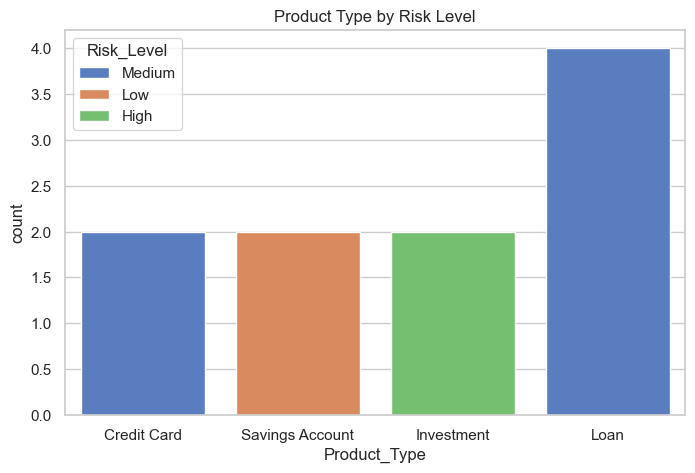

In [31]:
# -----------------------------
# 4. Exploratory Data Analysis
# -----------------------------

## Product Offering Analysis
plt.figure(figsize=(8,5))
sns.countplot(data=product_df, x="Product_Type", hue="Risk_Level")
plt.title("Product Type by Risk Level")
plt.show()

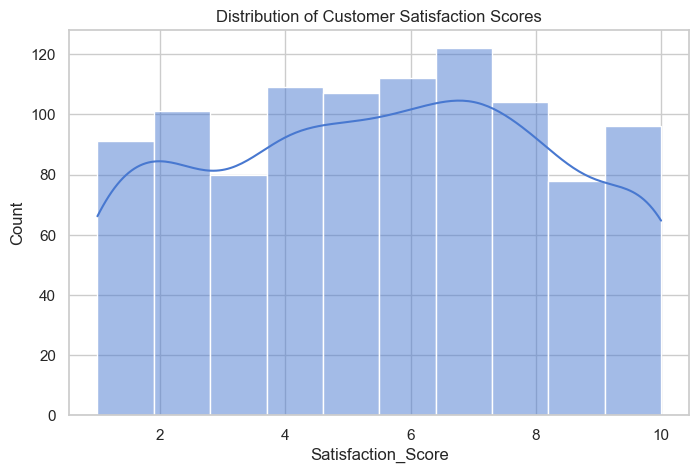

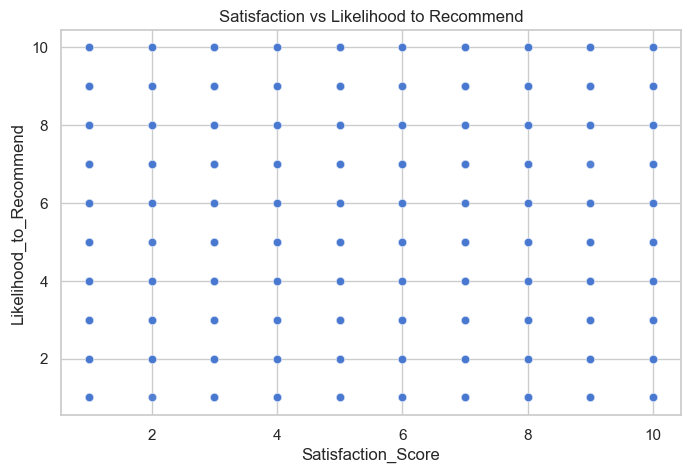

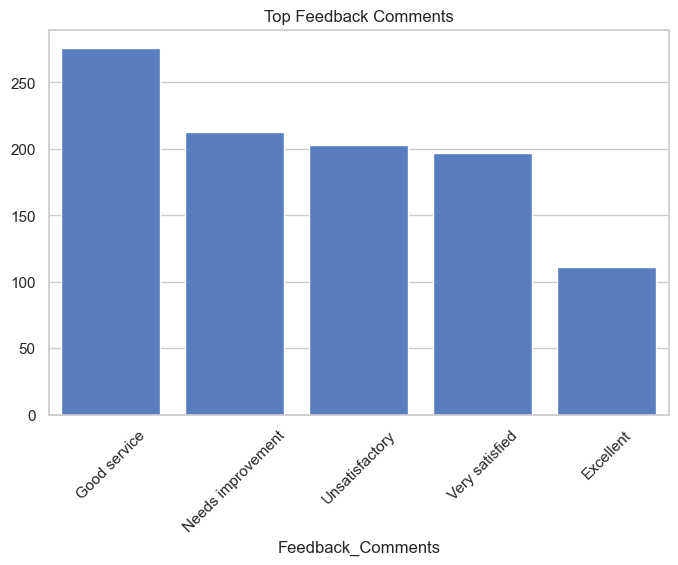

In [34]:
## Customer Feedback Analysis
plt.figure(figsize=(8,5))
sns.histplot(feedback_df["Satisfaction_Score"], bins=10, kde=True)
plt.title("Distribution of Customer Satisfaction Scores")
plt.show()

plt.figure(figsize=(8,5))
sns.scatterplot(data=feedback_df, x="Satisfaction_Score", y="Likelihood_to_Recommend", alpha=0.6)
plt.title("Satisfaction vs Likelihood to Recommend")
plt.show()

sentiment_counts = feedback_df["Feedback_Comments"].value_counts()
plt.figure(figsize=(8,5))
sns.barplot(x=sentiment_counts.index[:10], y=sentiment_counts.values[:10])
plt.title("Top Feedback Comments")
plt.xticks(rotation=45)
plt.show()

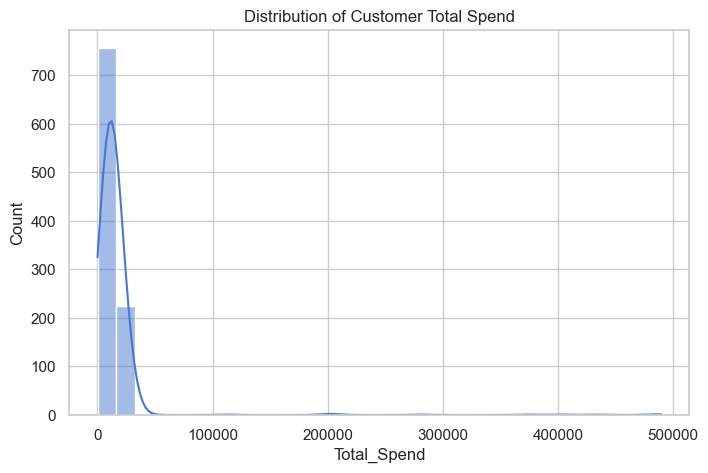

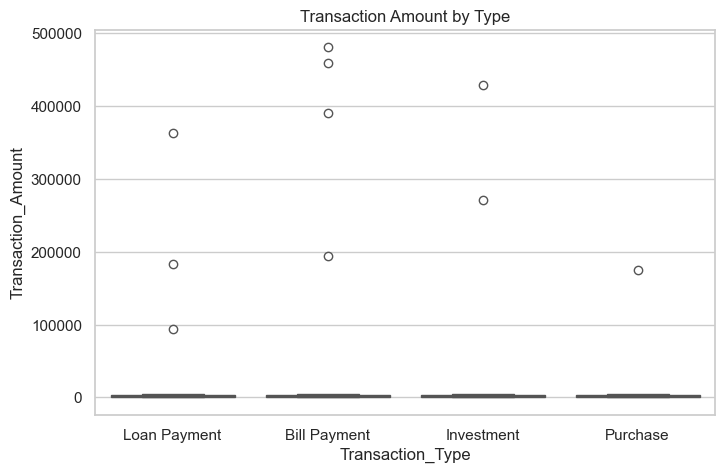

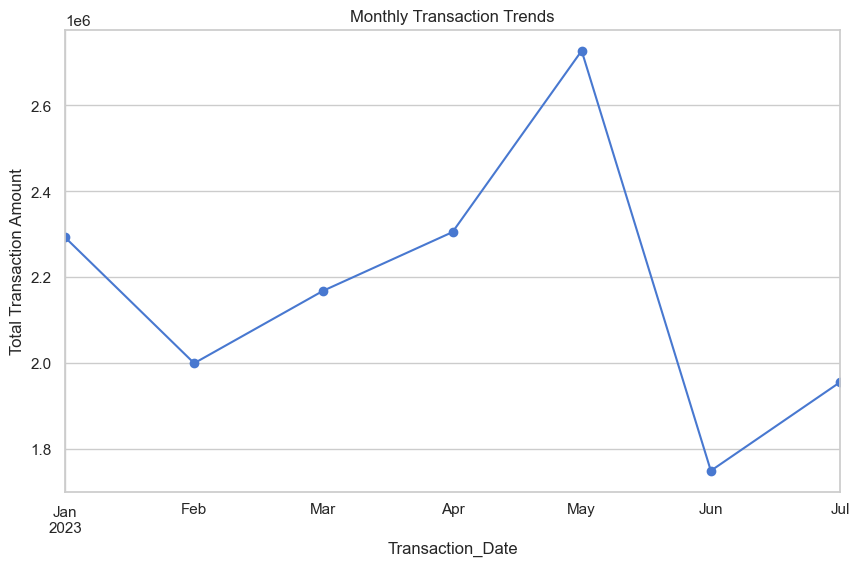

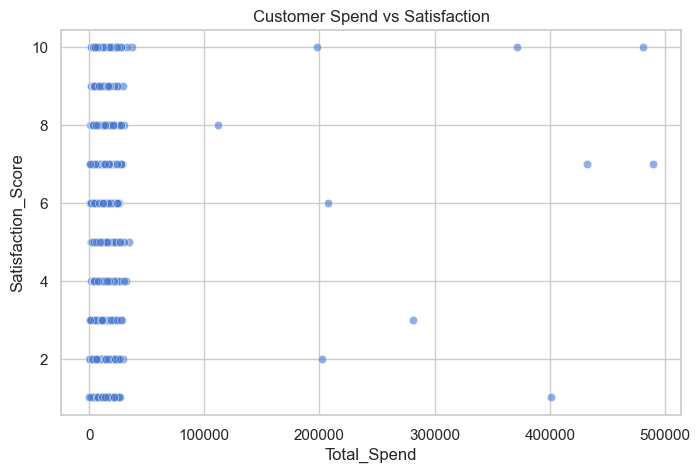

In [39]:
## Transaction Data Analysis
plt.figure(figsize=(8,5))
sns.histplot(customer_transactions["Total_Spend"], bins=30, kde=True)
plt.title("Distribution of Customer Total Spend")
plt.show()

plt.figure(figsize=(8,5))
sns.boxplot(data=transaction_df, x="Transaction_Type", y="Transaction_Amount")
plt.title("Transaction Amount by Type")
plt.show()

transaction_trends = transaction_df.groupby(transaction_df["Transaction_Date"].dt.to_period("M"))["Transaction_Amount"].sum()
transaction_trends.plot(kind="line", marker="o")
plt.title("Monthly Transaction Trends")
plt.ylabel("Total Transaction Amount")
plt.show()

plt.figure(figsize=(8,5))
sns.scatterplot(data=feedback_df, x="Total_Spend", y="Satisfaction_Score", alpha=0.6)
plt.title("Customer Spend vs Satisfaction")
plt.show()

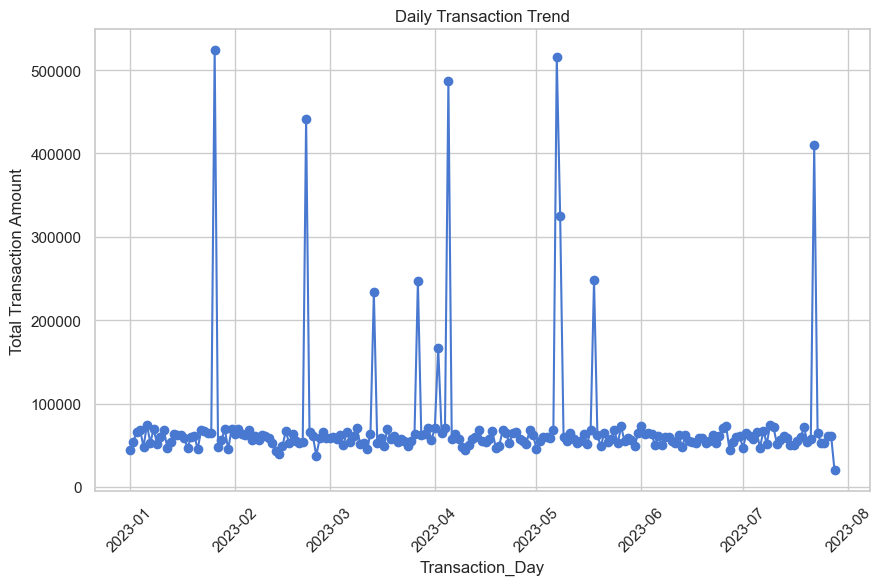

In [40]:
# --- New Visualizations for Engineered Features ---

# Daily Transaction Trend
daily_trend = transaction_df.groupby("Transaction_Day")["Transaction_Amount"].sum()
daily_trend.plot(kind="line", marker="o")
plt.title("Daily Transaction Trend")
plt.ylabel("Total Transaction Amount")
plt.xticks(rotation=45)
plt.show()

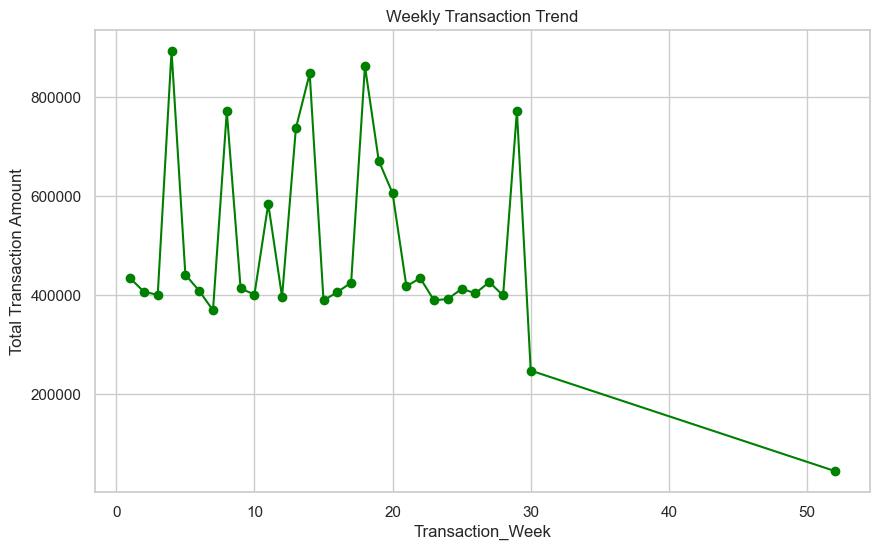

In [41]:
# Weekly Transaction Trend
weekly_trend = transaction_df.groupby("Transaction_Week")["Transaction_Amount"].sum()
weekly_trend.plot(kind="line", marker="o", color="green")
plt.title("Weekly Transaction Trend")
plt.ylabel("Total Transaction Amount")
plt.show()

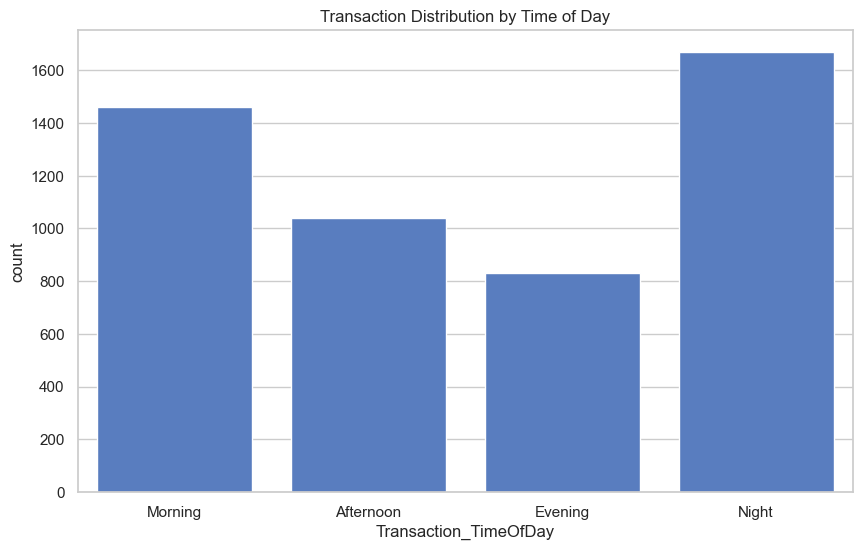

In [42]:
# Transaction Distribution by Time of Day
sns.countplot(data=transaction_df, x="Transaction_TimeOfDay", order=["Morning","Afternoon","Evening","Night"])
plt.title("Transaction Distribution by Time of Day")
plt.show()

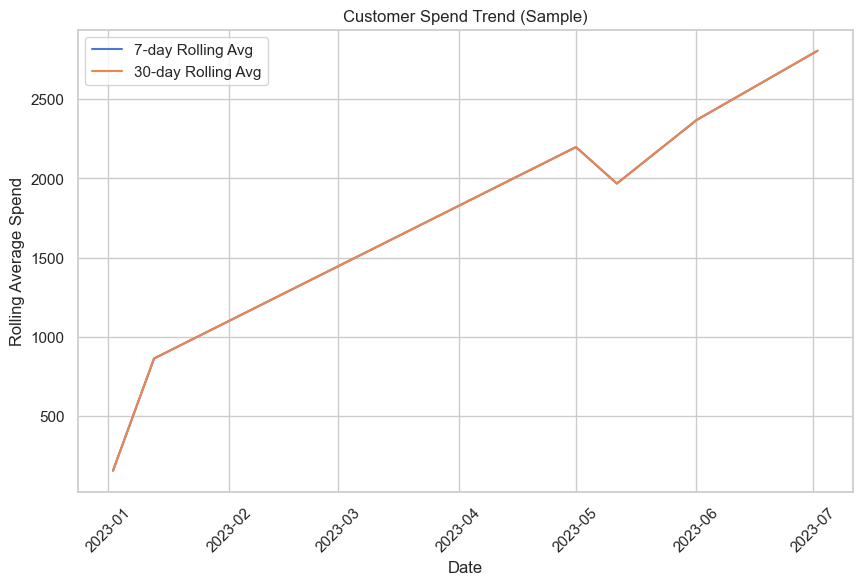

In [45]:
# Rolling Spend Trend for a sample customer
sample_customer = transaction_df[transaction_df["Customer_ID"] == transaction_df["Customer_ID"].iloc[0]]
plt.plot(sample_customer["Transaction_Date"], sample_customer["Daily_Spend_Trend"], label="7-day Rolling Avg")
plt.plot(sample_customer["Transaction_Date"], sample_customer["Weekly_Spend_Trend"], label="30-day Rolling Avg")
plt.title("Customer Spend Trend (Sample)")
plt.xlabel("Date")
plt.ylabel("Rolling Average Spend")
plt.legend()
plt.xticks(rotation=45)
plt.show()

In [46]:
# -----------------------------
# 5. Export Full Cleaned Data to CSV
# -----------------------------
product_df.to_csv("Cleaned_Product_Data.csv", index=False)
feedback_df.to_csv("Cleaned_Feedback_Data.csv", index=False)
transaction_df.to_csv("Cleaned_Transaction_Data.csv", index=False)
customer_transactions.to_csv("Customer_Transactions_Summary.csv", index=False)

# Merge feedback + transaction summary with engineered features
merged_df = feedback_df.copy()
merged_df = merged_df.merge(
    transaction_df[["Customer_ID","Transaction_Type","Transaction_Date","Transaction_Amount",
                    "Transaction_Day","Transaction_Week","Transaction_Month","Transaction_Year",
                    "Transaction_Hour","Transaction_TimeOfDay","Daily_Spend_Trend","Weekly_Spend_Trend"]],
    on="Customer_ID", how="left"
)

merged_df.to_csv("Merged_Cleaned_Dataset.csv", index=False)

print("\nCSV files have been exported:") 
print("- Cleaned_Product_Data.csv") 
print("- Cleaned_Feedback_Data.csv") 
print("- Cleaned_Transaction_Data.csv") 
print("- Customer_Transactions_Summary.csv") 
print("- Merged_Cleaned_Dataset.csv")


CSV files have been exported:
- Cleaned_Product_Data.csv
- Cleaned_Feedback_Data.csv
- Cleaned_Transaction_Data.csv
- Customer_Transactions_Summary.csv
- Merged_Cleaned_Dataset.csv


In [49]:
# -----------------------------
# 6. Data Quality Check (Valid vs Null Counts)
# -----------------------------

def check_nulls(df, name):
    print(f"\n{name} - Null Value Report")
    null_counts = df.isnull().sum()
    valid_counts = df.notnull().sum()
    report = pd.DataFrame({
        "Valid_Count": valid_counts,
        "Null_Count": null_counts
    })
    display(report)

# Run for each dataset
check_nulls(product_df, "Product Data (Cleaned)")
check_nulls(feedback_df, "Feedback Data (Cleaned)") 
check_nulls(transaction_df, "Transaction Data (Cleaned)") 
check_nulls(customer_transactions, "Customer Transactions Summary") 
check_nulls(merged_df, "Merged Dataset")


Product Data (Cleaned) - Null Value Report


,Valid_Count,Null_Count
Product_ID,10,0
Product_Name,10,0
Product_Type,10,0
Risk_Level,10,0
Target_Income_Group,10,0



Feedback Data (Cleaned) - Null Value Report


,Valid_Count,Null_Count
Customer_ID,1000,0
Satisfaction_Score,1000,0
Feedback_Comments,1000,0
Likelihood_to_Recommend,1000,0
Total_Spend_x,993,7
Total_Spend_y,993,7
Segment,1000,0
Total_Spend,993,7



Transaction Data (Cleaned) - Null Value Report


,Valid_Count,Null_Count
Transaction_ID,5000,0
Customer_ID,5000,0
Transaction_Date,5000,0
Transaction_Amount,5000,0
Transaction_Type,5000,0
Transaction_Day,5000,0
Transaction_Week,5000,0
Transaction_Month,5000,0
Transaction_Year,5000,0
Transaction_Hour,5000,0



Customer Transactions Summary - Null Value Report


,Valid_Count,Null_Count
Customer_ID,993,0
Total_Spend,993,0



Merged Dataset - Null Value Report


,Valid_Count,Null_Count
Customer_ID,5007,0
Satisfaction_Score,5007,0
Feedback_Comments,5007,0
Likelihood_to_Recommend,5007,0
Total_Spend_x,5000,7
Total_Spend_y,5000,7
Segment,5007,0
Total_Spend,5000,7
Transaction_Type,5000,7
Transaction_Date,5000,7
